# Praktikum Data Mining — Langkah Pengerjaan (Bagian 4)
**Evaluasi Model Klasifikasi: Confusion Matrix, Accuracy, Precision, Recall dan F1-Score**

Nama: AUDITYA MEROSYA PUTRI | NIM: 24343001 

Nama: Muhammad Zahran       | NIM: 24343077

Nama: Muhammad Riyad Anwari | NIM: 24343044


Notebook ini mengikuti Bagian 4.1–4.8 pada modul. Jalankan sel dari atas ke bawah. Di bawah setiap sel kode terdapat **Analisis** berdasarkan output hasil eksekusi.

## 4.1 Menyiapkan Dataset Sintetis

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)

df = pd.DataFrame({'amount': amount.round(2), 'hour': hour,
                   'new_device': new_device, 'foreign_ip': foreign_ip,
                   'isFraud': isFraud})
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


**Analisis**

- Dataset terdiri dari **500 transaksi** dengan 4 fitur (`amount`, `hour`, `new_device`, `foreign_ip`) dan 1 label (`isFraud`).
- Distribusi kelas: **484 normal dan 16 fraud**, sehingga proporsi fraud hanya **3,2%**. Dataset ini **sangat tidak seimbang** (*imbalanced*).
- Pada rumus `score`, IP luar negeri (1,5) paling besar pengaruhnya, lalu perangkat baru (1,1), jam dini hari < 05.00 (0,7), dan nominal > 300 (0,45). Intersep -4,5 membuat peluang fraud dasar sangat kecil, itulah sebabnya fraud langka.
- Karena memakai `default_rng(42)`, hasil dapat direproduksi.

## 4.2 Membagi Data dan Melatih Model

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Data latih:', len(y_train))
print('Data uji:', len(y_test))
print('Distribusi data uji:', y_test.value_counts().to_dict())

Data latih: 350
Data uji: 150
Distribusi data uji: {0: 145, 1: 5}


**Analisis**

- Data dibagi 70:30, yaitu 350 data latih dan **150 data uji**, sesuai output yang diharapkan modul.
- Karena `stratify=y`, proporsi kelas terjaga. Data uji berisi **145 normal dan hanya 5 fraud**.
- Dengan hanya 5 fraud di data uji, satu prediksi saja mengubah recall sebesar 20 poin persentase (1/5). Metrik kelas fraud di notebook ini **sangat sensitif dan kurang stabil**, sehingga kesimpulan perlu dibaca hati-hati.
- `class_weight='balanced'` memberi bobot lebih besar pada kelas fraud agar tidak diabaikan. `max_depth=4` membatasi kompleksitas pohon.

## 4.3 Menghitung Confusion Matrix

In [3]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


**Analisis**

Hasil: **TP = 2, TN = 113, FP = 32, FN = 3** (total 150).

- Dari 5 fraud aktual, model menangkap **2** (TP) dan melewatkan **3** (FN).
- Dari 145 transaksi normal, **113** dikenali benar (TN), tetapi **32** salah ditandai fraud (FP).
- FP (32) jauh lebih banyak daripada TP (2): mayoritas alarm fraud adalah alarm palsu, yang membebani tim verifikasi dan mengganggu pelanggan.
- Nilai ini dibaca dari output kode, bukan dari contoh manual di modul.

## 4.4 Perhitungan Manual dan Verifikasi

In [4]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test, y_pred), precision_score(y_test, y_pred, zero_division=0),
      recall_score(y_test, y_pred, zero_division=0), f1_score(y_test, y_pred, zero_division=0))

Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
0.7666666666666667 0.058823529411764705 0.4 0.10256410256410256


**Analisis**

| Metrik | Perhitungan | Hasil |
|---|---|---|
| Accuracy | (2+113)/150 | 0,767 (76,7%) |
| Precision | 2/(2+32) | 0,059 (5,9%) |
| Recall | 2/(2+3) | 0,400 (40%) |
| F1-score | 2×0,059×0,4/(0,059+0,4) | 0,103 |

- Perhitungan manual dan fungsi scikit-learn **menghasilkan nilai yang sama**, sehingga rumus dan pembacaan confusion matrix sudah benar.
- Accuracy 76,7% tampak cukup, tetapi **precision hanya 5,9%**: dari 34 alarm fraud, hanya 2 yang benar. Recall 40% berarti kurang dari separuh fraud tertangkap. F1 rendah (0,103) merangkum lemahnya kedua aspek.

## 4.5 Visualisasi Confusion Matrix

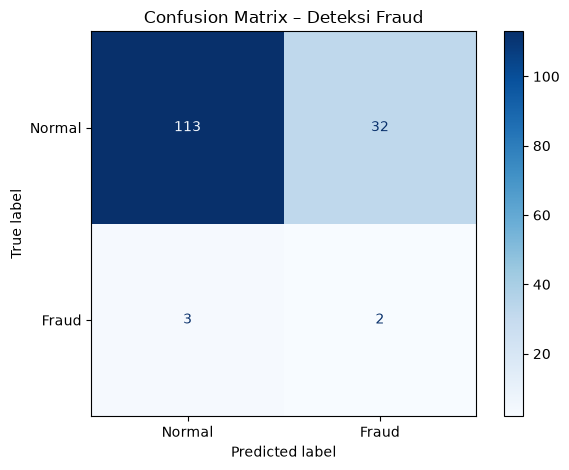

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal', 'Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

**Analisis (Gambar 1)**

- **Sel FN (kiri-bawah, = 3):** fraud aktual yang diprediksi normal. Fraud lolos dan berpotensi menimbulkan kerugian finansial. Dari 5 fraud, 3 lolos (60%).
- **Sel FP (kanan-atas, = 32):** transaksi normal yang diprediksi fraud. Konsekuensinya alarm palsu, pelanggan terganggu, dan beban verifikasi bertambah. Sekitar 22% transaksi normal terkena alarm palsu (32/145).
- Diagonal utama (TN=113, TP=2) adalah prediksi benar. Warna pekat hanya pada sel TN, mencerminkan dominasi kelas normal.

## 4.6 Interpretasi dan Studi Kasus

**Analisis**

- Pada deteksi fraud, **FN** (fraud lolos) berisiko menimbulkan kerugian langsung, sedangkan **FP** menurunkan pengalaman pelanggan dan menambah biaya operasional.
- Model ini punya **FN = 3 dan FP = 32**: cukup "agresif" menandai fraud (banyak FP) tetapi recall masih rendah (40%). Model **belum baik pada kedua sisi**.
- Penyebab yang masuk akal: fraud sangat jarang (16 di seluruh data, sekitar 11 di data latih), sehingga pohon sulit mempelajari pola yang andal.
- Pemilihan metrik harus mengikuti biaya kesalahan: bila FN jauh lebih mahal, recall menjadi prioritas, dengan konsekuensi alarm palsu bertambah.

## 4.7 Eksperimen: Baseline Semua Normal

In [6]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



**Analisis**

| Model | Accuracy | Precision fraud | Recall fraud | F1 fraud |
|---|---|---|---|---|
| Baseline (semua normal) | **0,967** | 0,00 | **0,00** | 0,00 |
| Decision Tree | 0,767 | 0,06 | **0,40** | 0,10 |

- Baseline yang selalu menebak normal mencapai accuracy **96,7%**, lebih tinggi daripada Decision Tree (76,7%), karena 145 dari 150 data uji memang normal.
- Namun **recall fraud baseline = 0**: tidak ada fraud yang terdeteksi, sehingga model ini tidak berguna untuk tujuan sebenarnya.
- Decision Tree menangkap 2 dari 5 fraud (**recall 0,40**) sehingga secara fungsional lebih berguna, walau dengan banyak alarm palsu.
- Pada data tidak seimbang, accuracy didominasi kelas mayoritas. Gunakan recall, precision, dan F1 kelas fraud.

## 4.8 Eksperimen: Pengaruh Ambang Prediksi

In [7]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
print('Nilai probabilitas unik:', np.unique(y_prob).round(3))
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test, pred, zero_division=0), 3),
          'recall=', round(recall_score(y_test, pred, zero_division=0), 3))

Nilai probabilitas unik: [0.    0.183 0.542 0.849 0.939 1.   ]
0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2


**Analisis**

| Threshold | Precision | Recall |
|---|---|---|
| 0,2 | 0,059 | 0,40 |
| 0,4 | 0,059 | 0,40 |
| 0,5 | 0,059 | 0,40 |
| 0,7 | 0,056 | 0,20 |

- Threshold **0,2, 0,4, dan 0,5 menghasilkan hasil yang sama**. Pohon dengan `max_depth=4` hanya menghasilkan probabilitas diskret (0; 0,18; 0,54; 0,85; 0,94; 1), sehingga tidak ada prediksi yang berubah di antara 0,2 dan 0,5.
- Pada **0,7**, recall turun menjadi 0,20 sementara precision hampir tidak berubah (0,056).
- Jadi menurunkan threshold tidak selalu menaikkan recall. Pada model ini hasilnya baru berubah ketika threshold melewati salah satu nilai probabilitas diskret tersebut. Ini sesuai catatan modul bahwa pola dapat tidak monoton pada dataset kecil.